<a href="https://colab.research.google.com/github/nuri-as/mnII/blob/main/Crank_Nicolson%20(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

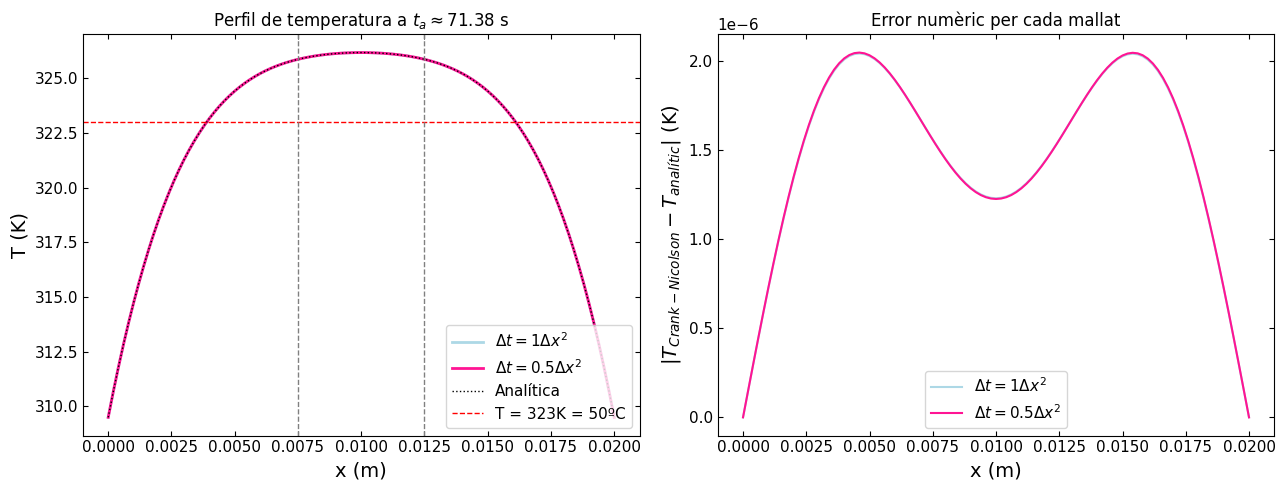

In [2]:
import numpy as np
import matplotlib.pyplot as plt


#Definim primer les condicions inicials
Tcos = 36.5 + 273 #K, temperatura inicial i a la frontera
z = 0.56 #W/(m*K)
cv = 3698 #J/(kg*K)
rho = 1081 #kg/m^3
sigma = 0.472 #S/m
alpha = z/(cv*rho)
Delta_V = 40 #V

#enunciat
t_max=0.025
N=101

#Constants de normalització
T0 = sigma * (Delta_V)**2 / (2*z)
d = 0.02 #m, gruix de paret entre els ventricles
t0 = d**2/alpha

"""
SOLUCIÓ ANALÍTICA
"""

# Definim la funció per calcular la solució analítica:
def T_analitica(x_tilde, t_tilde, Tcos, T0, n_termes):
  T= Tcos / T0 #terme de fora del sumatori

  #fem un for per calcular el sumatori:
  for n in range(1, n_termes + 1):
    p=(2*n-1)*np.pi
    ter_temp = (1.0 - np.exp(-(p**2) * t_tilde)) / (p**2)
    ter_pos = np.sin(p * x_tilde)

    T+= (4/p * ter_temp * ter_pos)
  return T

"""
CRANK-NICOLSON
"""
#mallats
h = [1,0.5] #ja que hem definit delta_t = h*(delta_x)**2
dx = 1/(N-1)
dt = [h[0]*(dx)**2,h[1]*(dx)**2 ]

xnorm = np.linspace(0,1,N)
Tcn = np.full(N, Tcos/T0)
#com hem fet amb l'esquema d'Euler implícit, definim uns paràmetres límits per les nostres iteracions
error_tol = 10**(-10) #fitem l'error que volem obtenir
max_iter = 10000 #limitem les iteracions realitzades
Tfinal = {}
errors = {}
colors = ["lightblue","deeppink"]
plt.rcParams.update({
    'xtick.labelsize': 11,
    'ytick.labelsize':11,
    'axes.labelsize': 14,
    'legend.fontsize': 11
})
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

#fem un bucle per calcular el resultat numèric pels dos mallats demanats
for k in range(len(dt)):
  Delta_t = dt[k]
  gamma = Delta_t/(dx)**2
  t_passes = int(t_max/Delta_t)
  Tcn = np.zeros((t_passes+1,N)) #definim una matriu buida amb t_passes+1 files, ja que amb aquest esquema calculem el terme j a partir del j-1, és a dir, per trobar el nostre ta desitjat necessitem anar fins a un terme superior
#Condicions inicials i de contorn
  Tcn[0,:] = Tcos/T0
  Tcn[:,0] = Tcos/T0
  Tcn[:,-1] = Tcos/T0
#Fem un ansatz, assumint que en el moment j la temperatura és igual a la que teniem al moment anterior j-1, anirem corregint-lo amb el mètode de Gauss-Seidel, tal i com hem fet a l'esquema d'Euler implicit
  for j in range(1,t_passes+1):
    Tcn[j,:] = Tcn[j-1,:].copy()
#Comencem el bucle iteratiu
    for it in range(max_iter):
      error_max = 0.0
      for i in range(1,N-1):
        Tnou = ((gamma/2)*(Tcn[j][i+1]+Tcn[j][i-1]+Tcn[j-1][i+1]+Tcn[j-1][i-1])+(1-gamma)*Tcn[j-1][i]+Delta_t)/(1+gamma) #Fórmula de l'esquema implícit de Crank-Nicolson
        error_max = max(error_max,np.abs(Tnou-Tcn[j][i]))
        Tcn[j][i] = Tnou
#Implementem la condició de frenada del nostre bucle en cas que la precissió demanada sigui sobrepassada
      if error_max < error_tol:
        break
#Guardem els resultats per cada valor de h
  Tfinal[h[k]] = Tcn[-1, :].copy()
#Invoquem la funció analítica per tal de comparar-les
  Tanal = T_analitica(xnorm,t_max,Tcos,T0,1000)
#Guardem també l'error per cada mallat
  errors[h[k]] = np.abs(Tcn[-1,:]-Tanal)
#Creem les respectives figures per cada mallat, desnormalitzant els valors multiplicant pel valor característic en cada cas
  ax[0].plot(d*xnorm, T0*Tfinal[h[k]], color=colors[k], linewidth=2, label=rf'$\Delta t={h[k]}\Delta x^2$')
  ax[1].plot(d*xnorm, errors[h[k]], color=colors[k], linewidth=1.5, label=rf"$\Delta t={h[k]}\Delta x^2$")
t_desnorm = t0*t_max


#grafiquem, aplicant els factors corresponents a cada cas per desnoramlitzar les magnituds

#gràfica solució analítica i numèrica

ax[0].plot(d*xnorm, T0*Tfinal[h[k]], ':', color='k', linewidth=1, label='Analítica')
ax[0].axhline(y=323, color='r', linestyle='--', linewidth=1, label='T = 323K = 50ºC') #fem una línia per veure que el teixit sa no excedeix d'aquesta temperatura
ax[0].axvline(x=0.0075, color='grey', linestyle='--', linewidth=1) #marquem els límits de la regió malalta
ax[0].axvline(x=0.0125, color='grey', linestyle='--', linewidth=1)

ax[0].set_title(rf"Perfil de temperatura a $t_a \approx {t_desnorm:.2f}$ s") #no podem posar titols
ax[0].set_xlabel('x (m)')
ax[0].set_ylabel('T (K)')
#posem que surtin els guions a tots els eixos i vagin cap a dins:
ax[0].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[0].legend(loc='lower right')

#gràfica de l'error

ax[1].set_title("Error numèric per cada mallat") #no podem posar titols
ax[1].set_xlabel('x (m)')
ax[1].set_ylabel(r'$|T_{Crank-Nicolson} - T_{analític}|$ (K)')

#posem que surtin els guions a tots els eixos i vagin cap a dins:
ax[1].tick_params(axis='both', which='both', direction='in', top=True, right=True)
ax[1].legend()

plt.tight_layout()
plt.show()
